In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_excel("../data/sample_-_superstore.xls")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10194
Columns: 21


In [9]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [10]:
df.dtypes

Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State/Province               str
Postal Code               object
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object

In [11]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [12]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [13]:
df.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [15]:
today = pd.Timestamp.today().normalize()

future_orders = df[df["Order Date"] > today]

print("Future dated orders:", len(future_orders))


Future dated orders: 711


In [16]:
negative_profit = df[df["Profit"] < 0]

print("Transactions with losses:", len(negative_profit))

Transactions with losses: 1901


In [17]:
print("Negative sales:", (df["Sales"] < 0).sum())

print("Negative quantities:", (df["Quantity"] < 0).sum())

Negative sales: 0
Negative quantities: 0


In [18]:
df[["Sales", "Profit", "Quantity", "Discount"]].describe()

,Sales,Profit,Quantity,Discount
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,28.673417,3.791838,0.155385
std,619.906839,232.465115,2.228317,0.206249
min,0.444000,-6599.978000,1.000000,0.000000
25%,17.220000,1.760800,2.000000,0.000000
50%,53.910000,8.690000,3.000000,0.200000
75%,209.500000,29.297925,5.000000,0.200000
max,22638.480000,8399.976000,14.000000,0.800000


In [19]:
future_orders[["Order ID", "Order Date", "Sales", "Profit"]].head(10)

,Order ID,Order Date,Sales,Profit
9483,US-2026-108112,2026-11-15,339.136,0.0000
9484,US-2026-108112,2026-11-15,220.064,55.0160
9485,US-2026-122945,2026-11-16,17.310,5.1930
9486,US-2026-157448,2026-11-16,12.420,4.4712
9487,US-2026-157448,2026-11-16,119.940,23.9880
9488,US-2026-107888,2026-11-16,139.920,23.7864
9489,US-2026-108091,2026-11-16,23.360,6.0736
9490,US-2026-160633,2026-11-16,86.352,5.3970
9491,US-2026-121678,2026-11-16,1.824,-1.3984
9492,US-2026-107888,2026-11-16,73.680,34.6296


In [20]:
print("Earliest order:", df["Order Date"].min())
print("Latest order:", df["Order Date"].max())

Earliest order: 2023-01-03 00:00:00
Latest order: 2026-12-30 00:00:00


In [21]:
print("Transactions with losses:", (df["Profit"] < 0).sum())

print("Negative sales:", (df["Sales"] < 0).sum())

print("Negative quantities:", (df["Quantity"] < 0).sum())

Transactions with losses: 1901
Negative sales: 0
Negative quantities: 0


In [22]:
future_orders["Order Date"].value_counts().sort_index()

Order Date
2026-11-15     2
2026-11-16    18
2026-11-17    16
2026-11-18    21
2026-11-19    26
2026-11-20    17
2026-11-21    15
2026-11-22     1
2026-11-23    17
2026-11-24    25
2026-11-25    13
2026-11-26    16
2026-11-27    13
2026-11-28    12
2026-11-29     2
2026-11-30    15
2026-12-01    34
2026-12-02    37
2026-12-03    20
2026-12-04    20
2026-12-05    19
2026-12-06     1
2026-12-07     9
2026-12-08    30
2026-12-09    35
2026-12-10    22
2026-12-11    22
2026-12-13     6
2026-12-14    23
2026-12-15     7
2026-12-16    13
2026-12-17    13
2026-12-18    20
2026-12-19     5
2026-12-20     6
2026-12-21    11
2026-12-22    27
2026-12-23    15
2026-12-24    16
2026-12-25    23
2026-12-26     4
2026-12-27     2
2026-12-28    19
2026-12-29    15
2026-12-30     8
Name: count, dtype: int64

In [23]:
future_orders["Order Date"].value_counts().sort_index()

Order Date
2026-11-15     2
2026-11-16    18
2026-11-17    16
2026-11-18    21
2026-11-19    26
2026-11-20    17
2026-11-21    15
2026-11-22     1
2026-11-23    17
2026-11-24    25
2026-11-25    13
2026-11-26    16
2026-11-27    13
2026-11-28    12
2026-11-29     2
2026-11-30    15
2026-12-01    34
2026-12-02    37
2026-12-03    20
2026-12-04    20
2026-12-05    19
2026-12-06     1
2026-12-07     9
2026-12-08    30
2026-12-09    35
2026-12-10    22
2026-12-11    22
2026-12-13     6
2026-12-14    23
2026-12-15     7
2026-12-16    13
2026-12-17    13
2026-12-18    20
2026-12-19     5
2026-12-20     6
2026-12-21    11
2026-12-22    27
2026-12-23    15
2026-12-24    16
2026-12-25    23
2026-12-26     4
2026-12-27     2
2026-12-28    19
2026-12-29    15
2026-12-30     8
Name: count, dtype: int64

In [24]:
today = pd.Timestamp.today().normalize()

clean_df = df[df["Order Date"] <= today].copy()

print("Original records:", len(df))
print("Records after filtering:", len(clean_df))
print("Records excluded:", len(df) - len(clean_df))

Original records: 10194
Records after filtering: 9483
Records excluded: 711


In [25]:
print("Latest order date:", clean_df["Order Date"].max())

print("Future orders remaining:",
      (clean_df["Order Date"] > today).sum())

Latest order date: 2026-11-14 00:00:00
Future orders remaining: 0


In [26]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9483 entries, 0 to 9482
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9483 non-null   int64         
 1   Order ID        9483 non-null   str           
 2   Order Date      9483 non-null   datetime64[us]
 3   Ship Date       9483 non-null   datetime64[us]
 4   Ship Mode       9483 non-null   str           
 5   Customer ID     9483 non-null   str           
 6   Customer Name   9483 non-null   str           
 7   Segment         9483 non-null   str           
 8   Country/Region  9483 non-null   str           
 9   City            9483 non-null   str           
 10  State/Province  9483 non-null   str           
 11  Postal Code     9483 non-null   object        
 12  Region          9483 non-null   str           
 13  Product ID      9483 non-null   str           
 14  Category        9483 non-null   str           
 15  Sub-Category   

# 1. Key Business Metrics

In [27]:
# Calculate key business metrics

total_sales = clean_df["Sales"].sum()

total_profit = clean_df["Profit"].sum()

total_orders = clean_df["Order ID"].nunique()

total_customers = clean_df["Customer ID"].nunique()

average_order_value = total_sales / total_orders

print("KEY BUSINESS METRICS")
print("-------------------------")

print("Total Sales:", round(total_sales, 2))

print("Total Profit:", round(total_profit, 2))

print("Total Orders:", total_orders)

print("Total Customers:", total_customers)

print("Average Order Value:", round(average_order_value, 2))

KEY BUSINESS METRICS
-------------------------
Total Sales: 2177727.36
Total Profit: 274266.26
Total Orders: 4746
Total Customers: 804
Average Order Value: 458.86


2. Category-wise Sales and Profit Analysis

In [28]:
category_analysis = clean_df.groupby("Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).round(2)

category_analysis = category_analysis.sort_values(
    by="Sales", ascending=False
)

category_analysis

,Sales,Profit,Quantity
Category,,,
Technology,791459.16,132698.56,6564
Furniture,702449.20,18458.46,7722
Office Supplies,683818.99,123109.25,21608


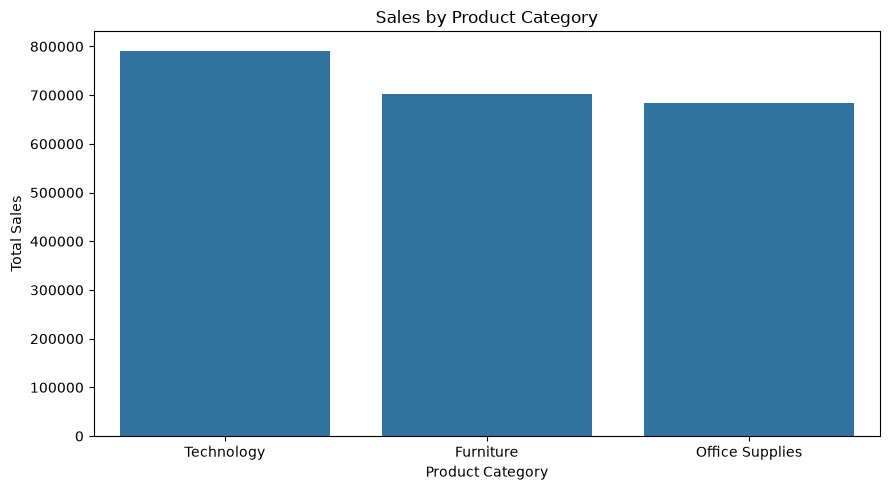

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Sales"
)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

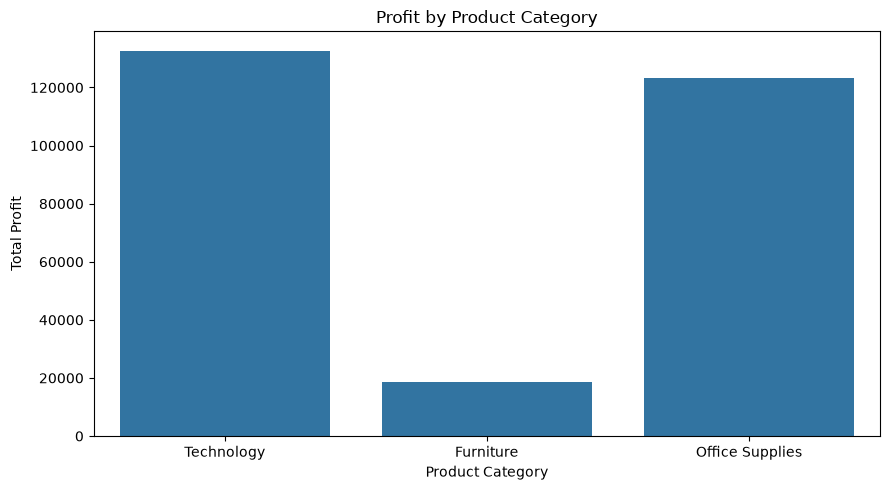

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Profit"
)

plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

# 3. Sub-Category Analysis


In [31]:
subcategory_analysis = clean_df.groupby("Sub-Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).round(2)

subcategory_analysis = subcategory_analysis.sort_values(
    by="Profit", ascending=False
)

subcategory_analysis

,Sales,Profit,Quantity
Sub-Category,,,
Copiers,132648.17,48429.87,217
Phones,312908.15,41132.80,3150
Accessories,160239.19,39978.23,2770
Binders,198139.19,35751.74,5625
Paper,73861.82,32068.53,4866
Chairs,313377.12,24552.81,2260
Storage,207965.44,18998.74,2966
Appliances,97645.64,17018.46,1607
Furnishings,85786.46,12559.31,3480


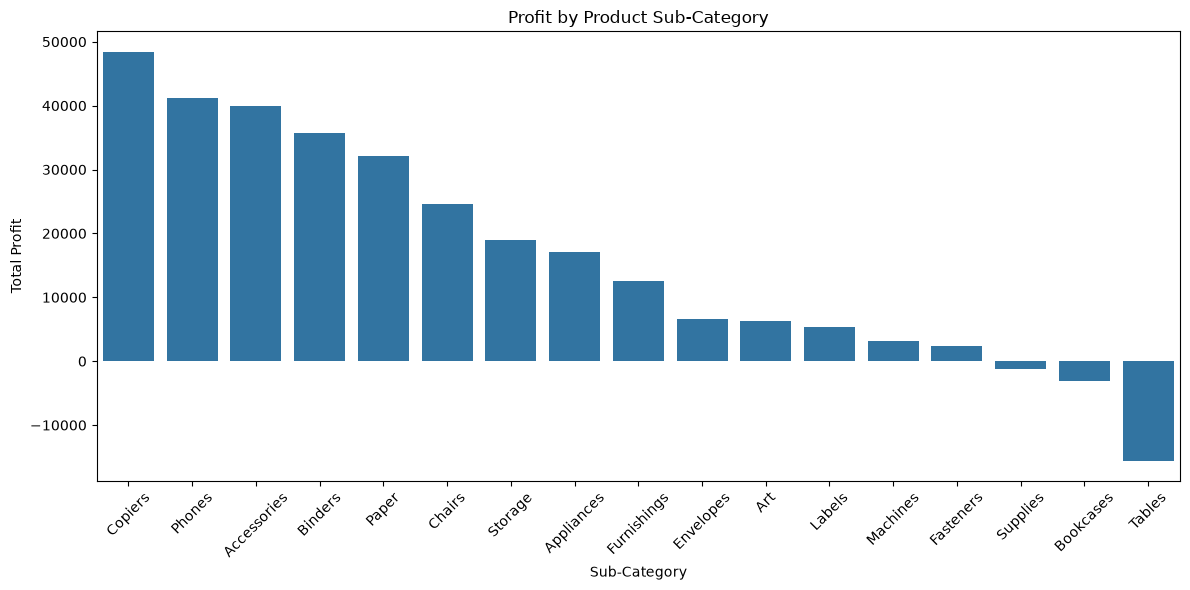

In [32]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=subcategory_analysis.reset_index(),
    x="Sub-Category",
    y="Profit"
)

plt.title("Profit by Product Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Key Business Insights

1. Copiers generate the highest profit among all sub-categories.
2. Phones and Accessories are also strong contributors to profitability.
3. Tables have the highest negative profit, indicating a significant business concern.
4. Bookcases and Supplies also generate negative profits.

**Business Recommendation:** The company should investigate the pricing, discount strategies and costs associated with Tables and Bookcases. It should also focus on maintaining the profitability of high-performing sub-categories such as Copiers, Phones and Accessories.


In [33]:
print("TOP 5 PROFITABLE SUB-CATEGORIES")

display(subcategory_analysis.nlargest(5, "Profit"))

print("BOTTOM 5 SUB-CATEGORIES")

display(subcategory_analysis.nsmallest(5, "Profit"))

TOP 5 PROFITABLE SUB-CATEGORIES


,Sales,Profit,Quantity
Sub-Category,,,
Copiers,132648.17,48429.87,217
Phones,312908.15,41132.80,3150
Accessories,160239.19,39978.23,2770
Binders,198139.19,35751.74,5625
Paper,73861.82,32068.53,4866


BOTTOM 5 SUB-CATEGORIES


,Sales,Profit,Quantity
Sub-Category,,,
Tables,193495.20,-15555.26,1168
Bookcases,109790.42,-3098.41,814
Supplies,44118.93,-1292.09,613
Fasteners,8207.82,2304.00,886
Machines,185663.65,3157.65,427


# 4. Regional Sales and Profit Analysis


In [34]:
region_analysis = clean_df.groupby("Region").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).round(2)

region_analysis.sort_values(
    by="Sales",
    ascending=False
)

,Sales,Profit,Quantity
Region,,,
West,701123.40,105409.99,11604
East,637109.25,83045.74,10276
Central,472842.13,42294.51,8240
South,366652.58,43516.02,5774


In [35]:
region_analysis["Profit Margin (%)"] = (
    region_analysis["Profit"] / region_analysis["Sales"]
) * 100

region_analysis.round(2)

,Sales,Profit,Quantity,Profit Margin (%)
Region,,,,
Central,472842.13,42294.51,8240,8.94
East,637109.25,83045.74,10276,13.03
South,366652.58,43516.02,5774,11.87
West,701123.40,105409.99,11604,15.03


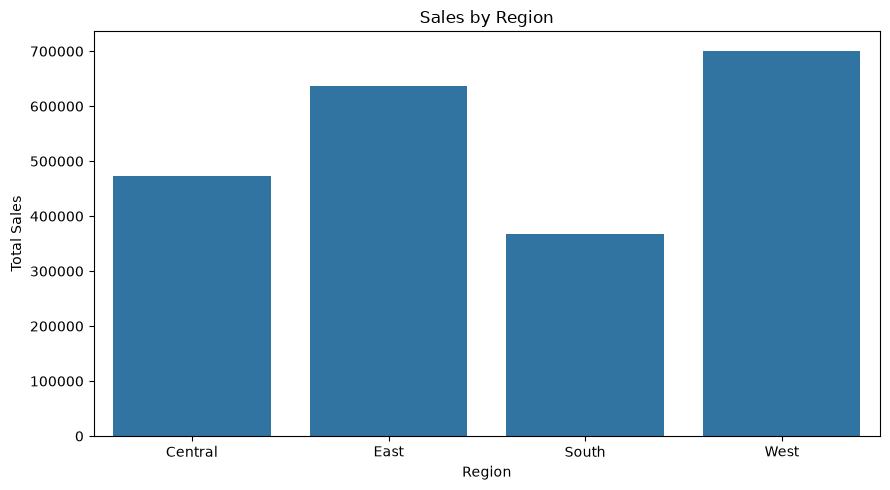

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Sales"
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

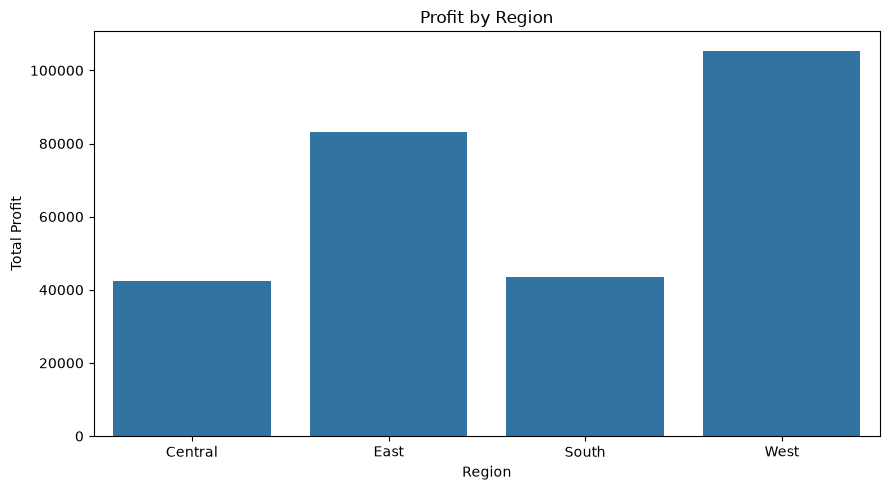

In [37]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Profit"
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

Regional Business Insights
1. West is the highest-performing region in terms of sales, profit and quantity.
2. East is the second-largest contributor to sales and profit.
3. Central has the lowest profit margin among the four regions.
4. South generates more profit than Central despite having lower sales.
Recommendation: The company should investigate Central's profitability and explore opportunities to increase sales in the South region.

5. Monthly Sales Trend Analysis

In [38]:
clean_df["Year-Month"] = clean_df["Order Date"].dt.to_period("M")

monthly_sales = clean_df.groupby("Year-Month").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Order ID": "nunique"
}).round(2)

monthly_sales.head()

,Sales,Profit,Order ID
Year-Month,,,
2023-01,14518.06,2539.39,33
2023-02,4519.89,862.31,28
2023-03,56933.91,693.45,72
2023-04,28295.34,3488.84,66
2023-05,26319.77,3196.39,72


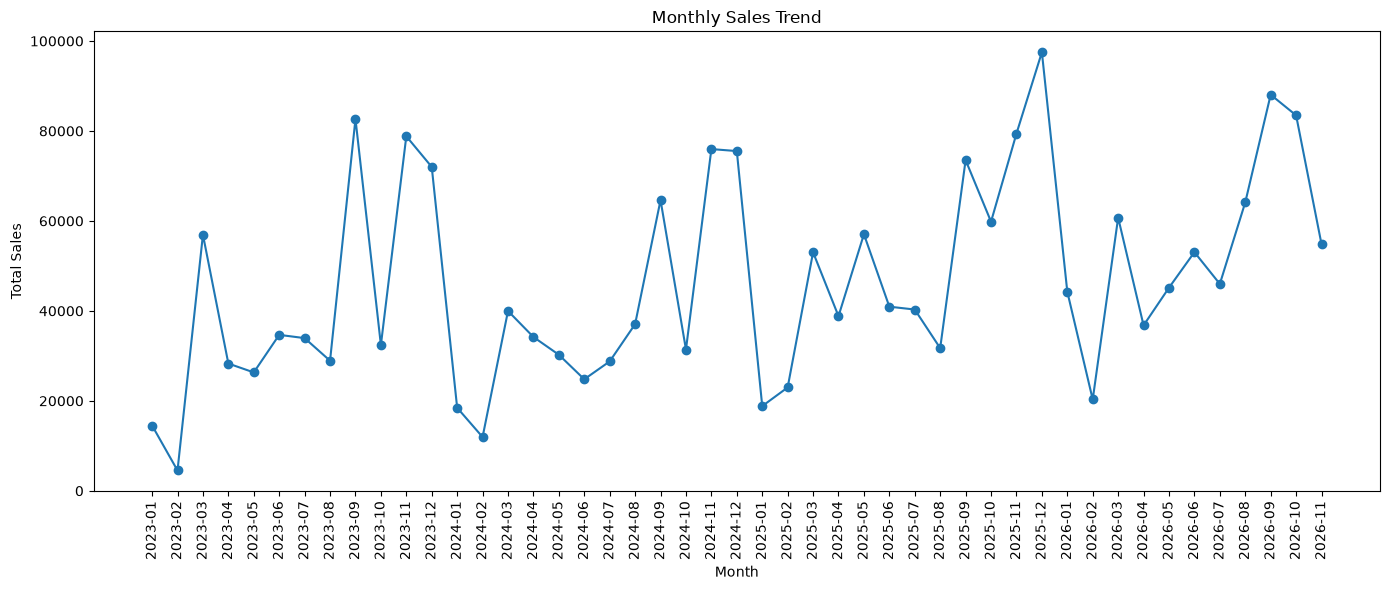

In [39]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [40]:
print("Highest Sales Month:")
print(monthly_sales["Sales"].idxmax())

print("Highest Sales:")
print(monthly_sales["Sales"].max())

Highest Sales Month:
2025-12
Highest Sales:
97502.28


In [41]:
print("Highest Sales Month:")
print(monthly_sales["Sales"].idxmax())

print("Highest Sales Value:")
print(round(monthly_sales["Sales"].max(), 2))

print("\nLowest Sales Month:")
print(monthly_sales["Sales"].idxmin())

print("Lowest Sales Value:")
print(round(monthly_sales["Sales"].min(), 2))

Highest Sales Month:
2025-12
Highest Sales Value:
97502.28

Lowest Sales Month:
2023-02
Lowest Sales Value:
4519.89


# 6. Customer Analysis

In [42]:
customer_analysis = clean_df.groupby("Customer Name").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Order ID": "nunique"
}).round(2)

top_customers = customer_analysis.sort_values(
    by="Sales",
    ascending=False
).head(10)

display(top_customers)

,Sales,Profit,Order ID
Customer Name,,,
Sean Miller,25043.05,-1980.74,5
Tamara Chand,19052.22,8981.32,5
Raymond Buch,15117.34,6976.10,6
Tom Ashbrook,14595.62,4703.79,4
Ken Lonsdale,14175.23,806.85,12
Sanjit Chand,14142.33,5757.41,9
Adrian Barton,13629.73,5220.36,9
Sanjit Engle,12085.08,2617.10,10
Christopher Conant,11902.43,2081.41,4


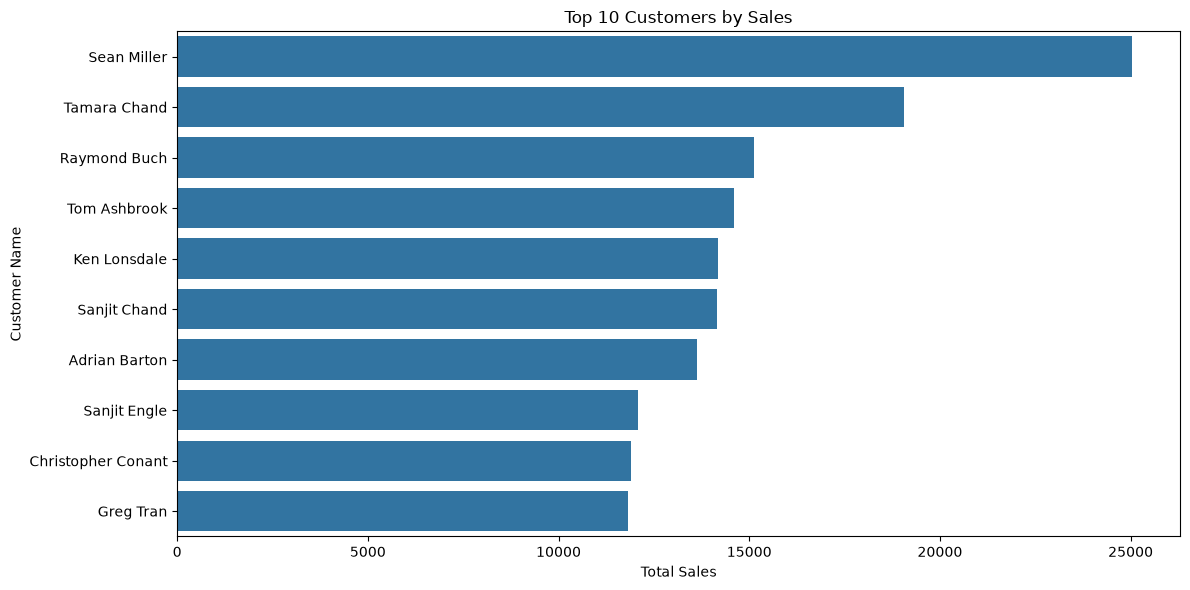

In [43]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers.reset_index(),
    x="Sales",
    y="Customer Name"
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.show()

### Key Customer Insights

1. Sean Miller is the highest-revenue customer among the top 10 customers but generates a negative profit.
2. Tamara Chand generates the highest profit among these customers.
3. Ken Lonsdale has the highest number of orders among the top 10 customers.
4. High customer revenue does not necessarily translate into high profitability.

**Business Recommendation:** Investigate the reasons behind losses associated with high-revenue customers. Review discounts, pricing and product profitability to improve customer-level profitability.

7. Discount and Profit Analysis

In [44]:
discount_analysis = clean_df.groupby("Discount").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).round(2)

display(discount_analysis)

,Sales,Profit,Quantity
Discount,,,
0.00,1021568.38,302328.55,17412
0.10,51318.60,8475.96,355
0.15,25594.10,1414.13,178
0.20,737919.40,86383.79,12879
0.30,96752.35,-9888.79,788
0.32,14086.87,-2365.08,101
0.40,109059.56,-21471.83,726
0.45,4763.10,-2073.11,39
0.50,57747.92,-19960.12,232


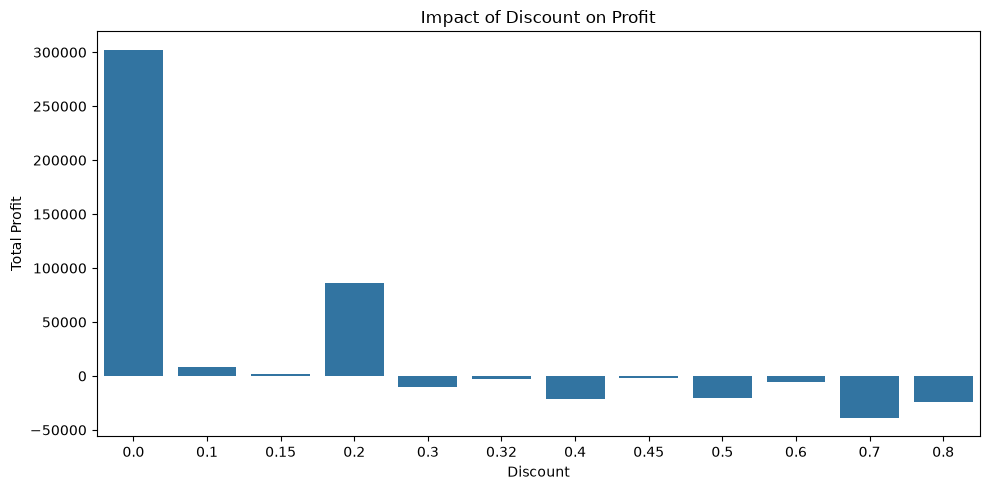

In [45]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis.reset_index(),
    x="Discount",
    y="Profit"
)

plt.title("Impact of Discount on Profit")
plt.xlabel("Discount")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

In [46]:
correlation = clean_df["Discount"].corr(clean_df["Profit"])

print("Discount-Profit Correlation:", round(correlation, 3))

Discount-Profit Correlation: -0.216


### Key Business Insights

1. Discount and profit have a weak negative correlation of -0.216.
2. Higher discounts tend to be associated with lower profits.
3. Discount levels alone do not fully explain profitability.
4. The company should evaluate discount policies alongside product categories and sales performance.

**Business Recommendation:** Review discount strategies and identify opportunities to improve profitability without negatively affecting sales.

 8. Final Sales Analytics Dashboard

In [47]:
total_sales = clean_df["Sales"].sum()
total_profit = clean_df["Profit"].sum()
total_orders = clean_df["Order ID"].nunique()
total_customers = clean_df["Customer ID"].nunique()
average_order_value = total_sales / total_orders

print("========== SALES DASHBOARD ==========")

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Customers: {total_customers}")
print(f"Average Order Value: {average_order_value:,.2f}")

========== SALES DASHBOARD ==========
Total Sales: 2,177,727.36
Total Profit: 274,266.26
Total Orders: 4746
Total Customers: 804
Average Order Value: 458.86


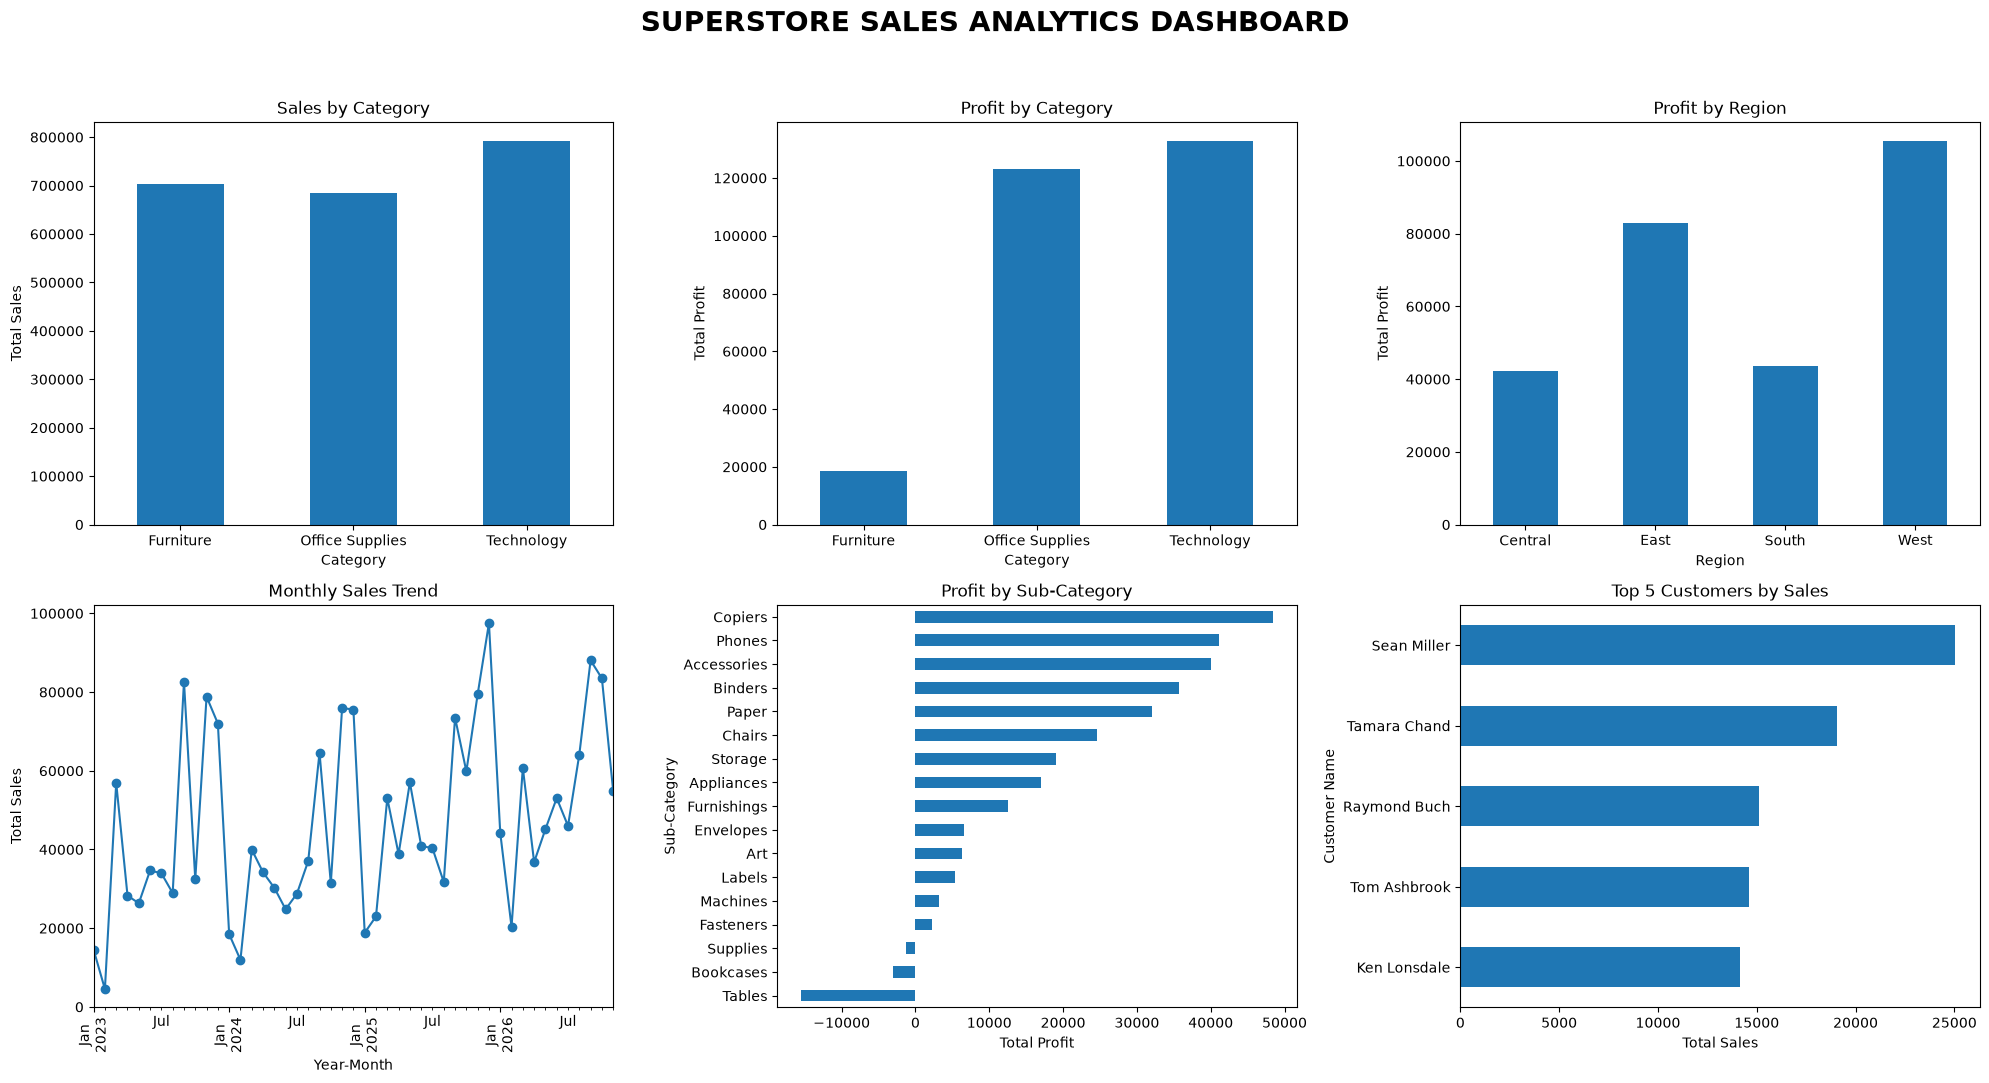

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

fig.suptitle(
    "SUPERSTORE SALES ANALYTICS DASHBOARD",
    fontsize=20,
    fontweight="bold"
)

# 1. Sales by Category
category_sales = clean_df.groupby("Category")["Sales"].sum()

category_sales.plot(
    kind="bar",
    ax=axes[0, 0],
    title="Sales by Category"
)

axes[0, 0].set_ylabel("Total Sales")
axes[0, 0].tick_params(axis="x", rotation=0)


# 2. Profit by Category
category_profit = clean_df.groupby("Category")["Profit"].sum()

category_profit.plot(
    kind="bar",
    ax=axes[0, 1],
    title="Profit by Category"
)

axes[0, 1].set_ylabel("Total Profit")
axes[0, 1].tick_params(axis="x", rotation=0)


# 3. Profit by Region
region_profit = clean_df.groupby("Region")["Profit"].sum()

region_profit.plot(
    kind="bar",
    ax=axes[0, 2],
    title="Profit by Region"
)

axes[0, 2].set_ylabel("Total Profit")
axes[0, 2].tick_params(axis="x", rotation=0)


# 4. Monthly Sales Trend
monthly_sales["Sales"].plot(
    kind="line",
    marker="o",
    ax=axes[1, 0],
    title="Monthly Sales Trend"
)

axes[1, 0].set_ylabel("Total Sales")
axes[1, 0].tick_params(axis="x", rotation=90)


# 5. Profit by Sub-Category
subcategory_analysis["Profit"].sort_values().plot(
    kind="barh",
    ax=axes[1, 1],
    title="Profit by Sub-Category"
)

axes[1, 1].set_xlabel("Total Profit")


# 6. Top 5 Customers
top_5_customers = customer_analysis.nlargest(5, "Sales")

top_5_customers["Sales"].sort_values().plot(
    kind="barh",
    ax=axes[1, 2],
    title="Top 5 Customers by Sales"
)

axes[1, 2].set_xlabel("Total Sales")


plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "../images/sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Key Business Insights

Based on the sales analysis, the following business insights were identified:

1. **Category Performance:** Technology generated the highest sales (₹791,459.16) and profit (₹132,698.56), making it the strongest category.

2. **Furniture Profitability:** Furniture generated ₹702,449.20 in sales but only ₹18,458.46 in profit. Its profitability needs improvement.

3. **Sub-Category Performance:** Copiers generated the highest profit. Tables, Bookcases and Supplies recorded negative profits and require further investigation.

4. **Regional Performance:** The West region recorded the highest sales and profit, while the Central region had the lowest profit.

5. **Monthly Sales Trends:** Sales fluctuated across months, with noticeable peaks and declines. These trends can help businesses plan inventory and promotions.

6. **Customer Analysis:** Sean Miller had the highest sales among the top 10 customers, but generated a loss of ₹1,980.74. High sales do not always mean high profitability.

7. **Discount Analysis:** The correlation between discount and profit was -0.216, indicating a weak negative relationship. Further analysis is needed before drawing conclusions about the effect of discounts.

### Business Recommendations

- Review pricing and discount strategies for low-profit products.
- Investigate the reasons behind losses in Tables, Bookcases and Supplies.
- Focus on maintaining strong performance in the Technology category.
- Study successful sales strategies in the West region.
- Monitor customer profitability, not just total customer sales.
- Use monthly sales trends to improve inventory and promotional planning.

**Note:** Historical analysis excludes 711 future-dated records. November 2026 is an incomplete month in this dataset.